# AgriScout — Results Analysis
Builds the hyperparameter tables and every report figure from `logs/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LOGS, FIGS = ROOT / "logs", ROOT / "assets" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
ALGOS = ["dqn", "reinforce", "ppo", "a2c"]


def load_runs():
    # Read every logged experiment into {algo: [records sorted by run name]}.
    runs = {a: [] for a in ALGOS}
    for f in sorted(LOGS.glob("*/*.json")):
        r = json.loads(f.read_text())
        runs[r["algo"]].append(r)
    return runs


runs = load_runs()
best = {a: max(rs, key=lambda r: r["eval_mean"]) for a, rs in runs.items() if rs}
{a: (len(rs), best[a]["run"], best[a]["eval_mean"]) for a, rs in runs.items()}

{'dqn': (12, 'r09_soft_target', 43.43),
 'reinforce': (11, 'r01_baseline', -58.29),
 'ppo': (11, 'r03_high_lr', 135.56),
 'a2c': (11, 'r10_big_rollout', -39.26)}

## Hyperparameter tables (report section 4)

In [2]:
TABLE_COLS = {
    "dqn": ["lr", "gamma", "buffer_size", "batch_size", "exploration", "target", "hidden"],
    "reinforce": ["lr", "gamma", "frames_per_batch", "baseline", "entropy_coef", "hidden"],
    "ppo": ["lr", "gamma", "clip_epsilon", "entropy_coef", "lmbda", "epochs", "frames_per_batch"],
    "a2c": ["lr", "gamma", "lmbda", "entropy_coef", "critic_coef", "frames_per_batch", "hidden"],
}


def table(algo):
    # One report-ready row per experiment, ending in the mean evaluated reward.
    rows = []
    for r in runs[algo]:
        cfg = dict(r["config"])
        cfg["exploration"] = f"eps {cfg.get('eps_init', '')}->{cfg.get('eps_end', '')} over {cfg.get('eps_anneal', '')}"
        row = {"run": r["run"]} | {c: str(cfg.get(c, "")) for c in TABLE_COLS[algo]}
        row |= {"mean_reward": r["eval_mean"], "std": r["eval_std"], "gen_reward": r["gen_mean"]}
        rows.append(row)
    df = pd.DataFrame(rows).sort_values("run").reset_index(drop=True)
    df.to_csv(LOGS / f"table_{algo}.csv", index=False)
    return df


for algo in ALGOS:
    if runs[algo]:
        print(f"=== {algo.upper()} ===")
        display(table(algo))

=== DQN ===


,run,lr,gamma,buffer_size,batch_size,exploration,target,hidden,mean_reward,std,gen_reward
0,r01_baseline,0.001,0.99,50000,128,eps 1.0->0.05 over 40000,hard,"[128, 128]",5.77,98.70,13.32
1,r02_low_lr,0.0001,0.99,50000,128,eps 1.0->0.05 over 40000,hard,"[128, 128]",-51.92,22.74,-79.86
2,r03_high_lr,0.005,0.99,50000,128,eps 1.0->0.05 over 40000,hard,"[128, 128]",-56.99,67.87,-25.38
3,r04_low_gamma,0.001,0.9,50000,128,eps 1.0->0.05 over 40000,hard,"[128, 128]",-71.93,74.60,-89.38
4,r05_tiny_buffer,0.001,0.99,2000,128,eps 1.0->0.05 over 40000,hard,"[128, 128]",-129.29,13.74,-151.35
5,r06_big_batch,0.001,0.99,50000,512,eps 1.0->0.05 over 40000,hard,"[128, 128]",-40.45,90.22,-16.32
6,r07_greedy_fast,0.001,0.99,50000,128,eps 1.0->0.01 over 5000,hard,"[128, 128]",-31.19,51.32,34.26
7,r08_explore_long,0.001,0.99,50000,128,eps 1.0->0.15 over 55000,hard,"[128, 128]",-113.14,29.72,-146.18
8,r09_soft_target,0.001,0.99,50000,128,eps 1.0->0.05 over 40000,soft,"[128, 128]",43.43,73.63,66.45
9,r10_slow_target,0.001,0.99,50000,128,eps 1.0->0.05 over 40000,hard,"[128, 128]",-53.25,72.42,-23.48


=== REINFORCE ===


,run,lr,gamma,frames_per_batch,baseline,entropy_coef,hidden,mean_reward,std,gen_reward
0,r01_baseline,0.001,0.99,2048,standardize,0.0,"[128, 128]",-58.29,27.01,-59.74
1,r02_low_lr,0.0001,0.99,2048,standardize,0.0,"[128, 128]",-119.94,5.04,-116.91
2,r03_high_lr,0.005,0.99,2048,standardize,0.0,"[128, 128]",-67.68,2.13,-67.57
3,r04_low_gamma,0.001,0.9,2048,standardize,0.0,"[128, 128]",-157.71,21.76,-179.33
4,r05_no_baseline,0.001,0.99,2048,none,0.0,"[128, 128]",-160.10,13.14,-181.80
5,r06_entropy,0.001,0.99,2048,standardize,0.01,"[128, 128]",-67.79,2.14,-67.87
6,r07_high_entropy,0.001,0.99,2048,standardize,0.05,"[128, 128]",-159.96,15.52,-181.26
7,r08_small_batch,0.001,0.99,512,standardize,0.0,"[128, 128]",-70.30,10.95,-79.86
8,r09_big_batch,0.001,0.99,8192,standardize,0.0,"[128, 128]",-75.16,15.59,-74.21
9,r10_small_net,0.001,0.99,2048,standardize,0.0,[64],-85.66,28.43,-83.78


=== PPO ===


,run,lr,gamma,clip_epsilon,entropy_coef,lmbda,epochs,frames_per_batch,mean_reward,std,gen_reward
0,r01_baseline,0.0003,0.99,0.2,0.01,0.95,4,1024,-54.09,23.61,-70.26
1,r02_low_lr,3e-05,0.99,0.2,0.01,0.95,4,1024,-77.56,28.27,-103.28
2,r03_high_lr,0.003,0.99,0.2,0.01,0.95,4,1024,135.56,20.81,153.32
3,r04_tight_clip,0.0003,0.99,0.1,0.01,0.95,4,1024,-41.26,14.30,-65.25
4,r05_loose_clip,0.0003,0.99,0.4,0.01,0.95,4,1024,-47.21,14.18,-58.74
5,r06_no_entropy,0.0003,0.99,0.2,0.0,0.95,4,1024,-62.93,15.12,-69.48
6,r07_high_entropy,0.0003,0.99,0.2,0.05,0.95,4,1024,24.91,54.20,74.87
7,r08_low_lambda,0.0003,0.99,0.2,0.01,0.8,4,1024,-50.35,14.34,-61.94
8,r09_many_epochs,0.0003,0.99,0.2,0.01,0.95,10,1024,50.63,55.69,96.34
9,r10_big_rollout,0.0003,0.99,0.2,0.01,0.95,4,4096,-41.69,13.76,-63.22


=== A2C ===


,run,lr,gamma,lmbda,entropy_coef,critic_coef,frames_per_batch,hidden,mean_reward,std,gen_reward
0,r01_baseline,0.0007,0.99,0.95,0.01,0.5,256,"[128, 128]",-42.65,11.89,-56.81
1,r02_low_lr,7e-05,0.99,0.95,0.01,0.5,256,"[128, 128]",-164.00,6.88,-181.85
2,r03_high_lr,0.003,0.99,0.95,0.01,0.5,256,"[128, 128]",-66.79,2.17,-66.75
3,r04_low_gamma,0.0007,0.9,0.95,0.01,0.5,256,"[128, 128]",-65.69,20.07,-88.82
4,r05_no_entropy,0.0007,0.99,0.95,0.0,0.5,256,"[128, 128]",-54.31,30.14,-91.85
5,r06_high_entropy,0.0007,0.99,0.95,0.05,0.5,256,"[128, 128]",-72.07,18.82,-91.63
6,r07_td_advantage,0.0007,0.99,0.0,0.01,0.5,256,"[128, 128]",-123.39,9.82,-141.32
7,r08_mc_advantage,0.0007,0.99,1.0,0.01,0.5,256,"[128, 128]",-43.61,15.71,-58.57
8,r09_small_rollout,0.0007,0.99,0.95,0.01,0.5,64,"[128, 128]",-58.49,40.74,-61.32
9,r10_big_rollout,0.0007,0.99,0.95,0.01,0.5,1024,"[128, 128]",-39.26,7.17,-57.42


## Cumulative rewards — best model per method (report 5a)

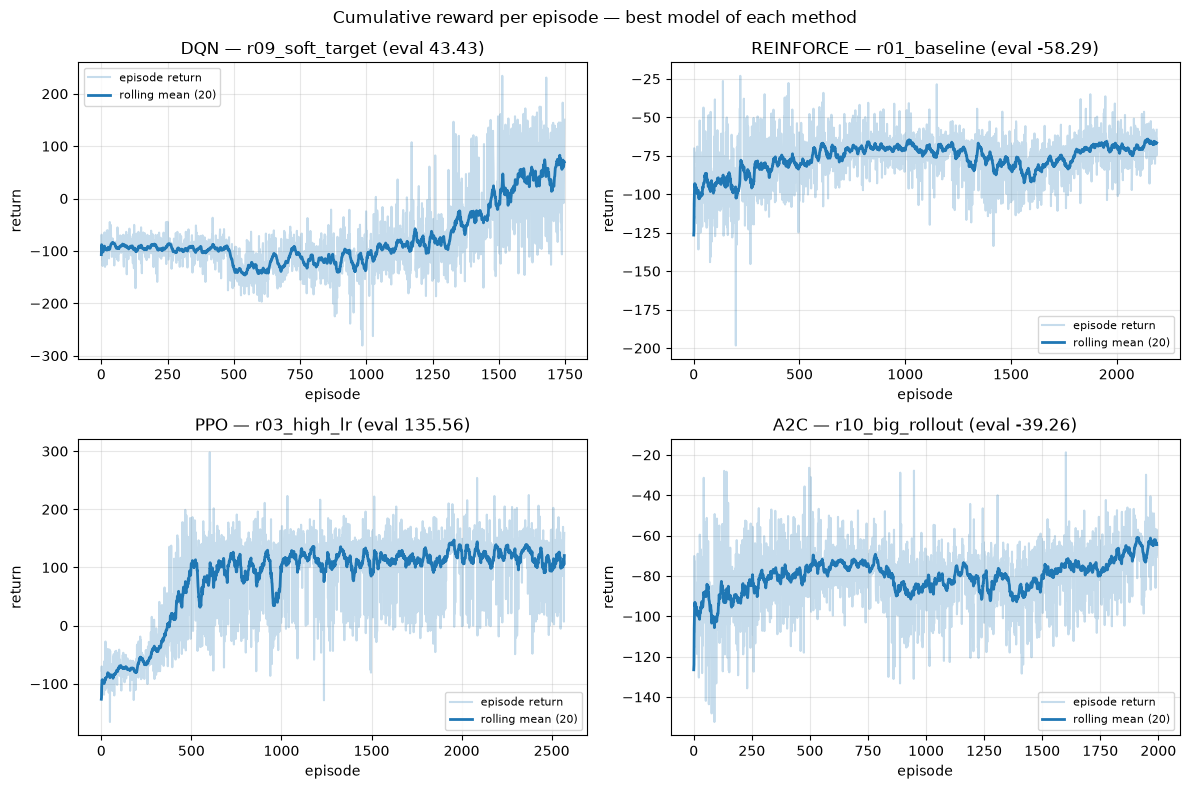

In [3]:
def smooth(x, w=20):
    # Rolling mean used for all learning curves.
    return pd.Series(x).rolling(w, min_periods=1).mean()


fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=False)
for ax, algo in zip(axes.flat, ALGOS):
    r = best[algo]
    returns = r["episode_returns"]
    ax.plot(returns, alpha=0.25, color="tab:blue", label="episode return")
    ax.plot(smooth(returns), color="tab:blue", lw=2, label="rolling mean (20)")
    ax.set_title(f"{algo.upper()} — {r['run']} (eval {r['eval_mean']})")
    ax.set_xlabel("episode")
    ax.set_ylabel("return")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.suptitle("Cumulative reward per episode — best model of each method")
fig.tight_layout()
fig.savefig(FIGS / "cumulative_rewards.png", dpi=150)

## Training stability — DQN loss and policy-gradient entropy (report 5a)

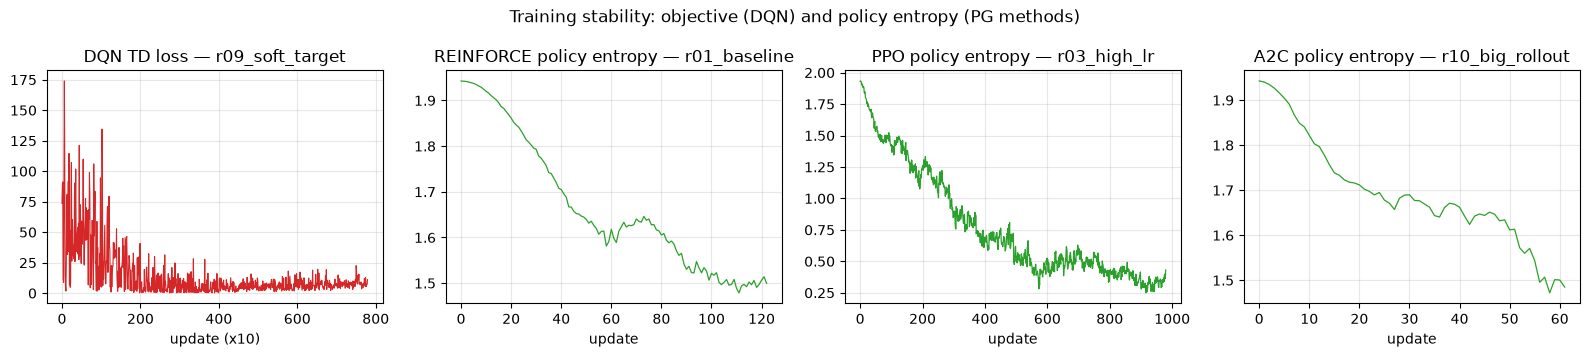

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].plot(best["dqn"]["curves"]["loss"], color="tab:red", lw=0.8)
axes[0].set_title(f"DQN TD loss — {best['dqn']['run']}")
axes[0].set_xlabel("update (x10)")
for ax, algo in zip(axes[1:], ["reinforce", "ppo", "a2c"]):
    ax.plot(best[algo]["curves"]["entropy"], color="tab:green", lw=0.9)
    ax.set_title(f"{algo.upper()} policy entropy — {best[algo]['run']}")
    ax.set_xlabel("update")
for ax in axes:
    ax.grid(alpha=0.3)
fig.suptitle("Training stability: objective (DQN) and policy entropy (PG methods)")
fig.tight_layout()
fig.savefig(FIGS / "stability.png", dpi=150)

## Episodes to converge (report 5b)

,algo,best_run,episodes_to_converge,final_rolling_mean
0,dqn,r09_soft_target,1513,70.1
1,reinforce,r01_baseline,415,-66.6
2,ppo,r03_high_lr,490,120.5
3,a2c,r10_big_rollout,512,-64.4


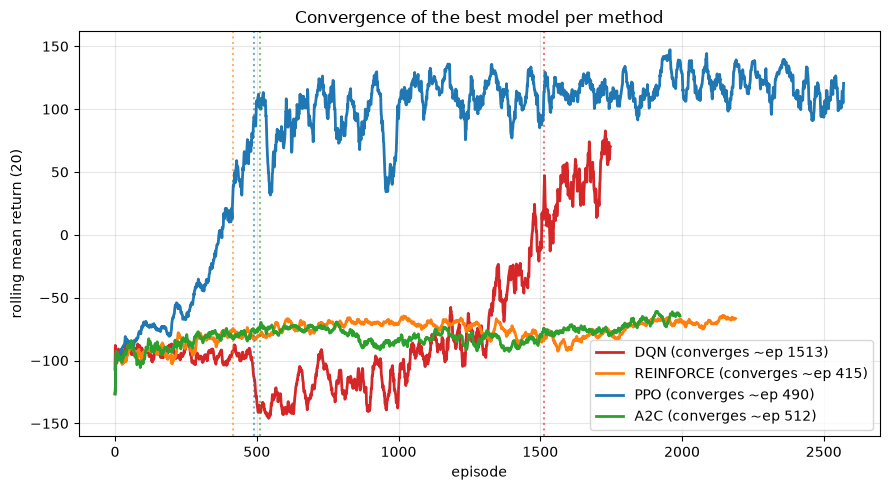

In [5]:
def convergence_episode(returns, w=20, frac=0.9):
    # First episode whose rolling mean reaches 90% of the final plateau.
    s = smooth(returns, w)
    target = s.iloc[-max(1, len(s) // 10):].mean()
    span = target - s.min()
    hits = np.where(s >= s.min() + frac * span)[0]
    return int(hits[0]) if len(hits) else len(s)


fig, ax = plt.subplots(figsize=(9, 5))
conv_rows = []
for algo, color in zip(ALGOS, ["tab:red", "tab:orange", "tab:blue", "tab:green"]):
    r = best[algo]
    s = smooth(r["episode_returns"])
    ep = convergence_episode(r["episode_returns"])
    ax.plot(s, label=f"{algo.upper()} (converges ~ep {ep})", color=color, lw=2)
    ax.axvline(ep, color=color, ls=":", alpha=0.6)
    conv_rows.append({"algo": algo, "best_run": r["run"], "episodes_to_converge": ep,
                      "final_rolling_mean": round(float(s.iloc[-1]), 1)})
ax.set_xlabel("episode")
ax.set_ylabel("rolling mean return (20)")
ax.set_title("Convergence of the best model per method")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGS / "convergence.png", dpi=150)
pd.DataFrame(conv_rows)

## Generalization — unseen start states (report 5c)

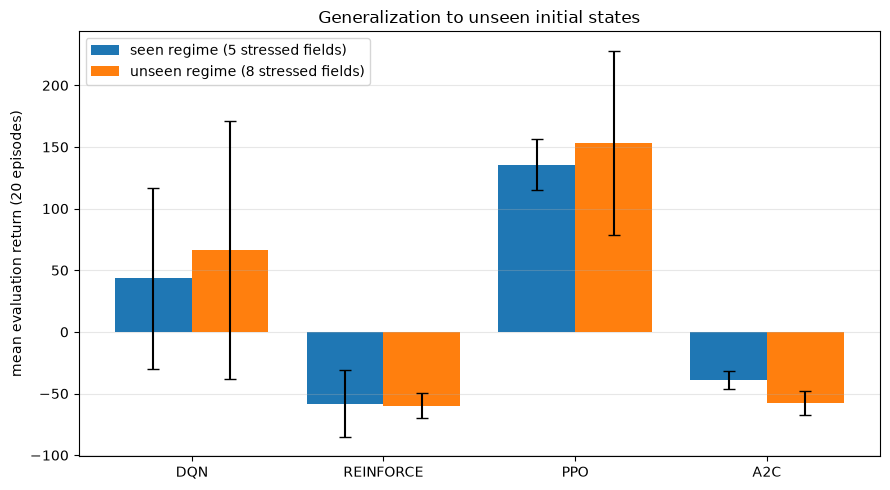

In [6]:
labels = [a.upper() for a in ALGOS]
eval_m = [best[a]["eval_mean"] for a in ALGOS]
eval_s = [best[a]["eval_std"] for a in ALGOS]
gen_m = [best[a]["gen_mean"] for a in ALGOS]
gen_s = [best[a]["gen_std"] for a in ALGOS]

x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - 0.2, eval_m, 0.4, yerr=eval_s, capsize=4, label="seen regime (5 stressed fields)")
ax.bar(x + 0.2, gen_m, 0.4, yerr=gen_s, capsize=4, label="unseen regime (8 stressed fields)")
ax.set_xticks(x, labels)
ax.set_ylabel("mean evaluation return (20 episodes)")
ax.set_title("Generalization to unseen initial states")
ax.legend()
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(FIGS / "generalization.png", dpi=150)